# Kinase-TF Correlated Group Panel


## 0. Imports & paths

In [1]:
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy import stats
import networkx as nx

CORR_METHOD    = "pearson"
CORR_R_THRESH  = 0
CORR_P_THRESH  = 0.05

psites_f  = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/TMT_control_centered_log2fc.csv"

# significant/dynamic phosphosites with geneSymbol, VMsiteFlanks, and
# is_tf all included directly -- same file used both here (for TF site
# identity) and as desites (for kinase dynamic-site filtering, unchanged
# below)
desites_f = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/significant_phospho_pairwise_ids_and_flanks.csv"

module_assignments_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_module_heatmap/out_files/kinase_module_assignments.csv"
# points at the isTF-corrected notebook's output -- site labels there are
# now individually-expanded (e.g. "Arid3a_S127s"/"Arid3a_T132t", not the
# old combined "Arid3a_S127sT132t"), so this MUST match that convention
# or site_label lookups below will silently fail to find anything
tf_module_summary_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/TFsite_module_heatmap/out_files/tf_module_overlap_summary.csv"

kinome_f = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/kinome_information.tsv"

out_dir = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression"
os.makedirs(out_dir, exist_ok=True)
os.makedirs(f"{out_dir}/figures", exist_ok=True)
os.makedirs(f"{out_dir}/out_files", exist_ok=True)

TOP_N_TF_SITES = 10

## 1. Load modules, TF-module associations, and dynamic (DE) sites

In [2]:
module_df = pd.read_csv(module_assignments_f)
module_ids = sorted(module_df["module"].unique())

tf_module_summary = pd.read_csv(tf_module_summary_f)

desites = pd.read_csv(desites_f)['id'].tolist()

prot_df = pd.read_csv(psites_f)
print(f"Modules: {len(module_ids)}  |  Dynamic sites: {len(desites)}  |  "
      f"Full proteomics table: {prot_df.shape}")

Modules: 12  |  Dynamic sites: 1220  |  Full proteomics table: (21641, 16)


## 2. Canonicalize module kinase names to gene symbols

`module_df["kinase"]` uses kinase_library's short-form names -- map to actual gene symbols before matching against `prot_df["geneSymbol"]`.

In [3]:
kinome = pd.read_csv(kinome_f, sep="\t")
kl_to_gene = dict(zip(kinome['KINASE'].str.upper(), kinome['GENE_NAME'].str.upper()))

module_df['kinase_gene'] = module_df['kinase'].str.upper().map(kl_to_gene)
n_unmapped = module_df['kinase_gene'].isna().sum()
if n_unmapped:
    unmapped_names = sorted(module_df.loc[module_df['kinase_gene'].isna(), 'kinase'].unique())
    print(f"WARNING: {n_unmapped} module kinases had no gene-symbol mapping "
          f"in kinome_information.tsv, falling back to kinase name as-is: {unmapped_names}")
    module_df.loc[module_df['kinase_gene'].isna(), 'kinase_gene'] = (
        module_df.loc[module_df['kinase_gene'].isna(), 'kinase'].str.upper()
    )

print(f"Module kinases: {len(module_df)}  |  Mapped to a gene symbol: {len(module_df) - n_unmapped}")

Module kinases: 83  |  Mapped to a gene symbol: 83


## 3. Rebuild dynamic TF sites (need full `id` to pull raw trajectory values)

In [4]:
import re

def split_site_tokens(combined_token):
    """Split a combined multi-site token like 'S127sT132t' into
    individual site tokens ['S127s', 'T132t']. A single-site token like
    'S136s' returns just ['S136s']."""
    return re.findall(r'[A-Z]\d+[a-z]', combined_token)


# same TF-identity source and multi-site expansion as the isTF-corrected
# tf_site_module_heatmap notebook -- site labels here MUST match that
# notebook's convention exactly, since tf_module_summary_f (loaded above)
# is keyed by those same expanded labels
tf_flag_sites = pd.read_csv(desites_f)

expanded_rows = []
n_mismatch = 0
for _, row in tf_flag_sites.iterrows():
    combined_site_token = row["id"].split("_")[1]
    site_tokens = split_site_tokens(combined_site_token)
    flanks = row["VMsiteFlanks"].split("|")

    if len(site_tokens) != len(flanks):
        n_mismatch += 1
        continue

    for site_token in site_tokens:
        expanded_rows.append({
            "id": row["id"], "geneSymbol": row["geneSymbol"],
            "site_token": site_token, "is_tf": row["is_tf"],
        })

if n_mismatch:
    print(f"WARNING: {n_mismatch} rows had a site-token/flank count mismatch, skipped")

dyn_sites_expanded = pd.DataFrame(expanded_rows)

dyn_tf_sites = dyn_sites_expanded.loc[dyn_sites_expanded["is_tf"] == True].copy().reset_index(drop=True)
dyn_tf_sites["site_label"] = dyn_tf_sites["geneSymbol"] + "_" + dyn_tf_sites["site_token"]
# same (gene, site_token) can arise from multiple original phosphopeptide
# rows (e.g. a residue reported standalone AND as part of a multi-site
# peptide) -- keep only the first occurrence rather than treating them
# as separate _dup-suffixed entities
n_before_dedup = len(dyn_tf_sites)
dyn_tf_sites = dyn_tf_sites.drop_duplicates(subset="site_label", keep="first").reset_index(drop=True)
print(f"TF sites: {n_before_dedup} -> {len(dyn_tf_sites)} after keeping only the first occurrence of each duplicated site_label")

site_label_to_id = dict(zip(dyn_tf_sites["site_label"], dyn_tf_sites["id"]))
print(f"Dynamic TF sites resolved: {len(site_label_to_id)}")

TF sites: 125 -> 120 after keeping only the first occurrence of each duplicated site_label
Dynamic TF sites resolved: 120


## 4. Trajectory and correlation helpers

In [5]:
time_order = ["0m", "20m", "45m", "90m"]

unstim_cols = [c for c in prot_df.columns if "PBS_0" in c]
il6_cols    = [c for c in prot_df.columns if "IL6" in c]
il10_cols   = [c for c in prot_df.columns if "IL10" in c]

cytokine_cols_map = {"IL6": il6_cols, "IL10": il10_cols}
CYTOKINE_COLOR = {"IL6": "#d62728", "IL10": "#1f77b4"}
x = np.arange(len(time_order))

def single_site_trajectory(row, cytokine_cols):
    vals = []
    for t in time_order:
        time_cols = unstim_cols if t == "0m" else [c for c in cytokine_cols if t.rstrip("m") in c]
        vals.append(row[time_cols].mean())
    return np.array(vals)

def paired_correlation(kinase_row, tf_row):
    """Pooled IL6+IL10 replicate samples, PBS excluded, n=12."""
    cols = il6_cols + il10_cols
    x_vals = kinase_row[cols].astype(float).values
    y_vals = tf_row[cols].astype(float).values
    if CORR_METHOD == "spearman":
        r, p = stats.spearmanr(x_vals, y_vals)
    else:
        r, p = stats.pearsonr(x_vals, y_vals)
    return r, p

def get_markers(n):
    """Distinct marker shapes for up to ~11 entities before repeating."""
    shapes = ['o', '^', 'v', '<', '>', 'p', 'h', '8', '*', 'X', 'P']
    return [shapes[i % len(shapes)] for i in range(n)]

## 5. Discover kinase-TF correlated groups per module

Same connected-component logic as before -- kinases that share a passing TF end up grouped together; an isolated kinase-TF pair forms its own singleton group, even within the same module. This step ONLY discovers groups and records their entities/correlations; no plotting happens here.

In [6]:
prot_df_genes_upper = set(prot_df["geneSymbol"].str.upper())
correlation_results = []
discovered_groups = []      # [{"module": m, "group_idx": i, "kinases": [...], "tfs": [...], "tf_best_r": {...}}]
kinase_row_by_label = {}    # global, across all modules

# Merge modules 5 and 6 into one combined "5_6" pseudo-module for THIS
# discovery step -- same meta-module grouping as the fig3a/tf_site_module
# heatmaps. Kinases from both modules get pooled together, and their
# combined candidate TF sites (top-4 by neg_log10_p across BOTH modules'
# Fisher's exact results, deduped) get used as one shared candidate pool
# -- discovery then runs ONCE for "5_6" instead of separately for 5 and
# separately for 6.
MODULE_MERGE = {5: "5_6", 6: "5_6"}

def display_module(m):
    return MODULE_MERGE.get(m, m)

merged_module_ids = sorted(
    set(display_module(m) for m in module_ids),
    key=lambda d: min(m for m in module_ids if display_module(m) == d),
)

for disp_m in merged_module_ids:
    raw_modules = [m for m in module_ids if display_module(m) == disp_m]

    kinase_genes = set(module_df.loc[module_df["module"].isin(raw_modules), "kinase_gene"])
    module_kinase_sites = prot_df[
        prot_df["geneSymbol"].str.upper().isin(kinase_genes) & prot_df["id"].isin(desites)
    ].copy()

    if module_kinase_sites.empty:
        continue

    module_kinase_sites["site_label"] = (
        module_kinase_sites["geneSymbol"].str.upper() + "_" + module_kinase_sites["id"].str.split("_").str[1]
    )
    dup_mask = module_kinase_sites["site_label"].duplicated(keep=False)
    if dup_mask.any():
        suffix = module_kinase_sites.groupby("site_label").cumcount().astype(str)
        module_kinase_sites.loc[dup_mask, "site_label"] += "_dup" + suffix[dup_mask]

    top_tf_rows = (
        tf_module_summary[tf_module_summary["module"].isin(raw_modules)]
        .sort_values("neg_log10_p", ascending=False)
        .drop_duplicates(subset="site_label")  # a site can appear for both merged modules
        .head(TOP_N_TF_SITES)
    )
    top_tf_sites = top_tf_rows["site_label"].tolist()

    print(f"\nModule {disp_m}: top-{TOP_N_TF_SITES} TF candidates selected")
    print(top_tf_rows[["site_label", "p_value", "neg_log10_p"]].to_string(index=False))

    passing_tfs_by_kinase = {}
    for _, kinase_row in module_kinase_sites.iterrows():
        kinase_label = kinase_row["site_label"]
        kinase_row_by_label[kinase_label] = kinase_row
        for tf_label in top_tf_sites:
            tf_site_id = site_label_to_id.get(tf_label)
            if tf_site_id is None or tf_site_id not in prot_df["id"].values:
                continue
            tf_row = prot_df.loc[prot_df["id"] == tf_site_id].iloc[0]

            r, p = paired_correlation(kinase_row, tf_row)
            passed = (abs(r) >= CORR_R_THRESH) and (p < CORR_P_THRESH)
            correlation_results.append({"module": disp_m, "kinase_site": kinase_label,
                                         "tf_site": tf_label, "r": r, "p_value": p, "passed": passed})
            if passed:
                passing_tfs_by_kinase.setdefault(kinase_label, []).append((tf_label, r, p))

    if not passing_tfs_by_kinase:
        continue

    G = nx.Graph()
    edge_r = {}
    for kinase_label, tf_hits in passing_tfs_by_kinase.items():
        for tf_label, r, p in tf_hits:
            G.add_edge(kinase_label, tf_label)
            edge_r[(kinase_label, tf_label)] = r

    components = sorted(nx.connected_components(G), key=len, reverse=True)
    for comp_idx, component in enumerate(components, start=1):
        kinases_in_plot = [n for n in component if n in passing_tfs_by_kinase]
        seen_tfs = [n for n in component if n not in passing_tfs_by_kinase]
        tf_best_r = {}
        for tf_label in seen_tfs:
            rs = [edge_r[(k, tf_label)] for k in kinases_in_plot if (k, tf_label) in edge_r]
            tf_best_r[tf_label] = max(rs, key=abs)

        discovered_groups.append({
            "module": disp_m, "group_idx": comp_idx,
            "kinases": kinases_in_plot, "tfs": seen_tfs, "tf_best_r": tf_best_r,
        })

corr_df = pd.DataFrame(correlation_results)
corr_df.to_csv(f"{out_dir}/out_files/kinase_tf_pair_correlations.csv", index=False)

print(f"Discovered groups by module:")
for grp in discovered_groups:
    print(f"  Module {grp['module']}, group {grp['group_idx']}: "
          f"kinases={grp['kinases']}, tfs={grp['tfs']}")


Module 1: top-10 TF candidates selected
  site_label  p_value  neg_log10_p
 FOXK1_S243s 0.000005     5.329374
   ERF_T529t 0.000005     5.329374
  CIC_S2311s 0.000005     5.304931
NFATC1_S766s 0.000132     3.879855
NFATC2_S739s 0.000213     3.671362
  HMGA2_S44s 0.000941     3.026612
 ZFP91_S106s 0.001115     2.952797
HMGXB4_S197s 0.001115     2.952797
 MIER1_S487s 0.001855     2.731696
 MEF2A_S235s 0.003398     2.468736

Module 2: top-10 TF candidates selected
  site_label  p_value  neg_log10_p
  TBX2_S704s 0.000001     5.886550
ARID5A_S552s 0.000412     3.385545
BCLAF1_S121s 0.000537     3.270290
 THAP4_S144s 0.001511     2.820611
  ZFP91_S86s 0.003309     2.480298
ZFP318_S670s 0.004881     2.311463
 NFIL3_S301s 0.004881     2.311463
  ETV3_S250s 0.013224     1.878649
ARID5A_S377s 0.016350     1.786471
  HMGA2_S44s 0.024059     1.618731

Module 5_6: top-10 TF candidates selected
  site_label  p_value  neg_log10_p
 IKZF1_S461s 0.000069     4.163885
  NFIC_S297s 0.000427     3.369386


## 5c. Stricter re-grouping -- require ALL TFs correlated with ALL kinases

The connected components above only require some PATH of passing
correlations linking everyone together -- a kinase can end up in the
same group as a TF it was never actually tested against directly,
purely through shared membership with other entities. This section
re-groups using a strictly stronger requirement: a **complete bipartite
subgraph (biclique)** -- every kinase in the group must individually
pass against every TF in the group, with no exceptions.

A connected component that's already fully biclique-connected produces
exactly one identical biclique. A component that's only loosely/
chain-connected splits into multiple smaller, denser bicliques -- some
entities may end up appearing in more than one biclique if they're
"hub" nodes connecting multiple otherwise-separate cliques.

Reuses corr_df directly (no new correlation testing) -- purely a
different way of grouping the same already-computed pairwise results.

In [7]:
from itertools import combinations

def find_maximal_bicliques(kinases, tfs, passing_pairs):
    """passing_pairs: set of (kinase, tf) tuples that passed the
    correlation test. Returns a list of (kinase_frozenset, tf_frozenset)
    -- every maximal complete bipartite subgraph within this group."""
    neighbor_tfs = {k: {t for t in tfs if (k, t) in passing_pairs} for k in kinases}

    candidates = set()
    for r in range(1, len(kinases) + 1):
        for kinase_subset in combinations(kinases, r):
            common_tfs = set.intersection(*(neighbor_tfs[k] for k in kinase_subset))
            if common_tfs:
                candidates.add((frozenset(kinase_subset), frozenset(common_tfs)))

    # keep only MAXIMAL bicliques -- drop any (k_set, t_set) that is
    # properly dominated by another candidate on BOTH sides at once
    maximal = []
    for k_set, t_set in candidates:
        dominated = any(
            (k_set, t_set) != (k_set2, t_set2) and k_set <= k_set2 and t_set <= t_set2
            for k_set2, t_set2 in candidates
        )
        if not dominated:
            maximal.append((k_set, t_set))
    return maximal


discovered_groups_biclique = []
for grp in discovered_groups:
    m = grp["module"]
    kinases = grp["kinases"]
    tfs = grp["tfs"]

    sub = corr_df[
        (corr_df["module"] == m) &
        (corr_df["kinase_site"].isin(kinases)) &
        (corr_df["tf_site"].isin(tfs)) &
        (corr_df["passed"])
    ]
    passing_pairs = set(zip(sub["kinase_site"], sub["tf_site"]))

    bicliques = find_maximal_bicliques(kinases, tfs, passing_pairs)

    for b_idx, (k_set, t_set) in enumerate(bicliques, start=1):
        tf_best_r = {
            tf: corr_df.loc[
                (corr_df["module"] == m) & (corr_df["tf_site"] == tf) & (corr_df["kinase_site"].isin(k_set)),
                "r"
            ].abs().max()
            for tf in t_set
        }
        discovered_groups_biclique.append({
            "module": m, "parent_group_idx": grp["group_idx"], "biclique_idx": b_idx,
            "kinases": sorted(k_set), "tfs": sorted(t_set), "tf_best_r": tf_best_r,
        })

print(f"Connected components: {len(discovered_groups)}  ->  Bicliques: {len(discovered_groups_biclique)}")
for g in discovered_groups_biclique:
    m = g["module"]
    pg = g["parent_group_idx"]
    bi = g["biclique_idx"]
    print(f"  Module {m} (from group {pg}, biclique {bi}): kinases={g['kinases']}, tfs={g['tfs']}")

Connected components: 10  ->  Bicliques: 18
  Module 1 (from group 1, biclique 1): kinases=['MTOR_S2450s', 'MTOR_S2478sS2481s'], tfs=['HMGA2_S44s', 'NFATC1_S766s', 'NFATC2_S739s']
  Module 1 (from group 1, biclique 2): kinases=['CDK13_T1056tT1058t', 'MTOR_S2450s'], tfs=['CIC_S2311s', 'HMGA2_S44s']
  Module 1 (from group 1, biclique 3): kinases=['CDK13_T1056tT1058t'], tfs=['CIC_S2311s', 'HMGA2_S44s', 'MIER1_S487s']
  Module 1 (from group 1, biclique 4): kinases=['MTOR_S2450s'], tfs=['CIC_S2311s', 'HMGA2_S44s', 'NFATC1_S766s', 'NFATC2_S739s']
  Module 1 (from group 1, biclique 5): kinases=['CDK13_T1056tT1058t', 'MTOR_S2450s', 'MTOR_S2478sS2481s'], tfs=['HMGA2_S44s']
  Module 1 (from group 2, biclique 1): kinases=['CDK13_S260s'], tfs=['ERF_T529t', 'FOXK1_S243s', 'HMGXB4_S197s', 'ZFP91_S106s']
  Module 2 (from group 1, biclique 1): kinases=['SRPK2_S491sT492t'], tfs=['ETV3_S250s', 'ZFP91_S86s']
  Module 2 (from group 1, biclique 2): kinases=['CLK1_S101s'], tfs=['ARID5A_S377s', 'ARID5A_S552s

## 6. Group-plotting function

Draws one group onto a given `ax` (marker=site identity, open=kinase/closed=TF, dashed=kinase/solid=TF, color=cytokine) -- refactored to take explicit kinase/TF label lists instead of always drawing a whole discovered group, so panels can show a hand-filtered subset.

In [8]:
def plot_group_on_ax(ax, kinases, tfs, tf_r_lookup, title):
    entities = kinases + tfs
    markers = get_markers(len(entities))
    entity_marker = dict(zip(entities, markers))

    # Markers much larger relative to line width, and drawn with zorder=3 so
    # they render ON TOP of the connecting lines -- otherwise a thick line
    # crossing through a marker can visually swallow it once the whole
    # figure is scaled down (e.g. shrunk in Illustrator).
    MARKERSIZE = 18
    MARKEREDGEWIDTH = 1.2
    LINEWIDTH = 1.2

    for cytokine, cytokine_cols in cytokine_cols_map.items():
        color = CYTOKINE_COLOR[cytokine]

        for kinase_label in kinases:
            kinase_row = kinase_row_by_label[kinase_label]
            traj = single_site_trajectory(kinase_row, cytokine_cols)
            ax.plot(x, traj, linestyle="--", linewidth=LINEWIDTH, color=color, zorder=1)
            ax.plot(x, traj, marker=entity_marker[kinase_label], markersize=MARKERSIZE,
                    linestyle="none", markerfacecolor="none", markeredgecolor=color,
                    markeredgewidth=MARKEREDGEWIDTH, zorder=3)

        for tf_label in tfs:
            tf_site_id = site_label_to_id.get(tf_label)
            tf_row = prot_df.loc[prot_df["id"] == tf_site_id].iloc[0]
            traj = single_site_trajectory(tf_row, cytokine_cols)
            ax.plot(x, traj, linestyle="-", linewidth=LINEWIDTH, color=color, zorder=1)
            ax.plot(x, traj, marker=entity_marker[tf_label], markersize=MARKERSIZE,
                    linestyle="none", markerfacecolor=color, markeredgecolor=color,
                    markeredgewidth=MARKEREDGEWIDTH, zorder=3)

    entity_handles = [
        plt.Line2D([0], [0], color="black", linestyle="--" if e in kinases else "-",
                   marker=entity_marker[e], markersize=MARKERSIZE,
                   markerfacecolor="none" if e in kinases else "black",
                   markeredgecolor="black", markeredgewidth=MARKEREDGEWIDTH,
                   label=f"{e}" + (" (kinase)" if e in kinases else " (TF)"))
        for e in entities
    ]
    cytokine_handles = [
        plt.Line2D([0], [0], color=CYTOKINE_COLOR[c], linewidth=2, label=c)
        for c in cytokine_cols_map
    ]
    ax.legend(handles=entity_handles + cytokine_handles, fontsize=6,
              loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)

    ax.set_xticks(x)
    ax.set_xticklabels(time_order)
    ax.set_xlabel("Time", fontsize=8)
    ax.set_ylabel("Phosphorylation (log2 FC)", fontsize=8)
    ax.set_title(title, fontsize=8.5)
    ax.tick_params(labelsize=7)

## 6b. Supplement panel -- every biclique, unfiltered

Every biclique discovered in Section 5c, exactly as found -- using the
stricter all-TFs-correlated-with-all-kinases grouping rather than the
looser connected components from Section 5. A single connected
component can appear here as several separate panels if it split into
multiple bicliques.

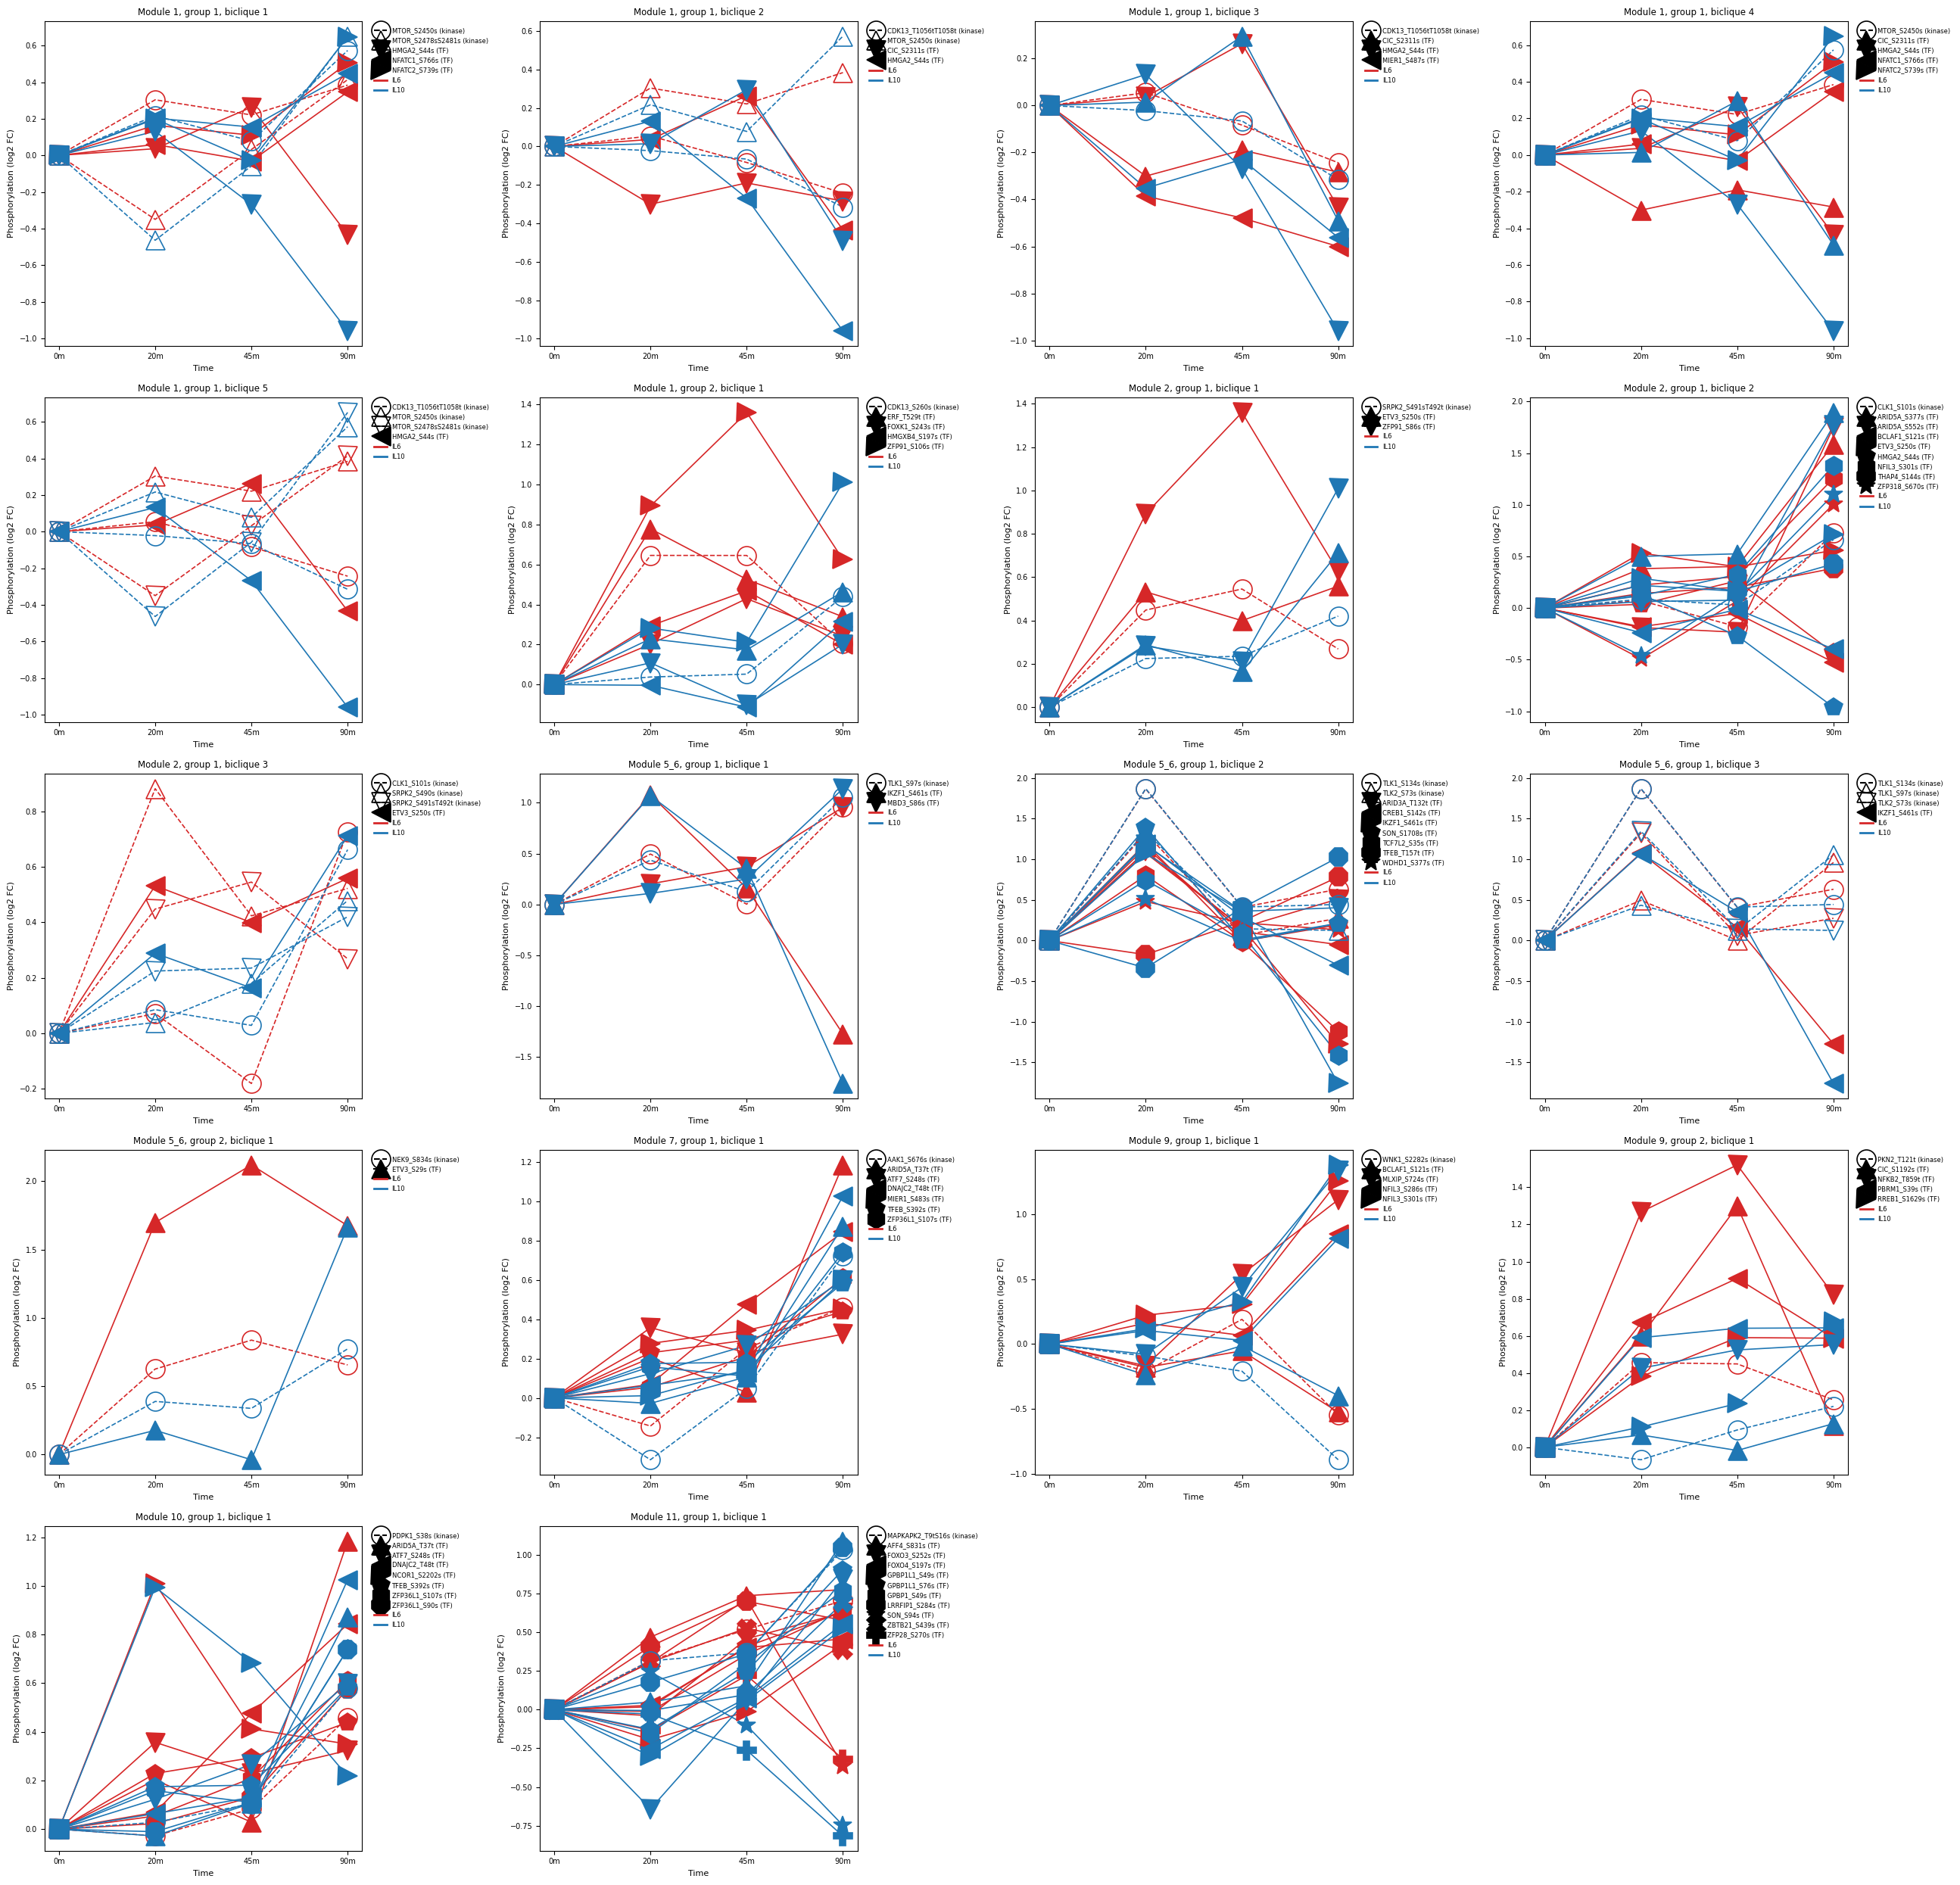

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_all_groups_panel_biclique.png  (18 groups)
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_all_groups_panel_biclique.svg


In [9]:
n_groups = len(discovered_groups_biclique)
ncols = 4
nrows = int(np.ceil(n_groups / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 5 * nrows))
axes = axes.flatten()

for ax, grp in zip(axes, discovered_groups_biclique):
    title = f"Module {grp['module']}, group {grp['parent_group_idx']}, biclique {grp['biclique_idx']}"
    plot_group_on_ax(ax, grp["kinases"], grp["tfs"], grp["tf_best_r"], title)

for j in range(len(discovered_groups_biclique), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()

png_out_supp = f"{out_dir}/figures/fig3d_all_groups_panel_biclique.png"
svg_out_supp = f"{out_dir}/figures/fig3d_all_groups_panel_biclique.svg"
plt.savefig(png_out_supp, dpi=300, bbox_inches="tight")
plt.savefig(svg_out_supp, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {png_out_supp}  ({n_groups} groups)")
print(f"Saved: {svg_out_supp}")

## 7. final panels -- 4 selected bicliques, saved INDIVIDUALLY

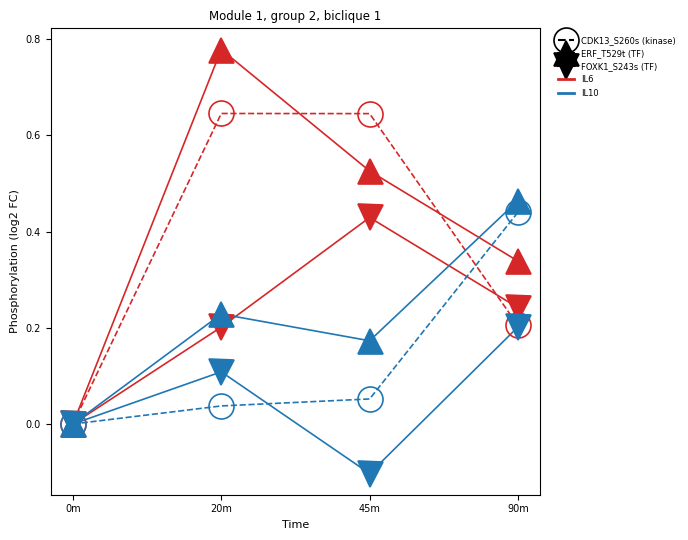

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module1_group2_biclique1.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module1_group2_biclique1.svg


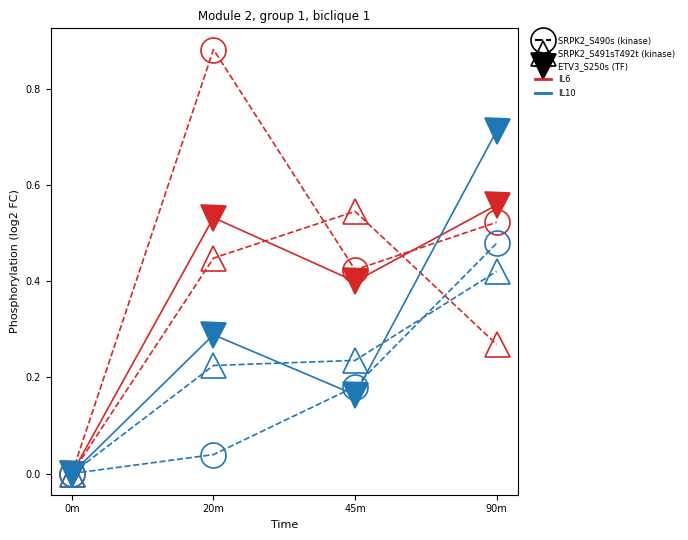

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module2_group1_biclique1.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module2_group1_biclique1.svg


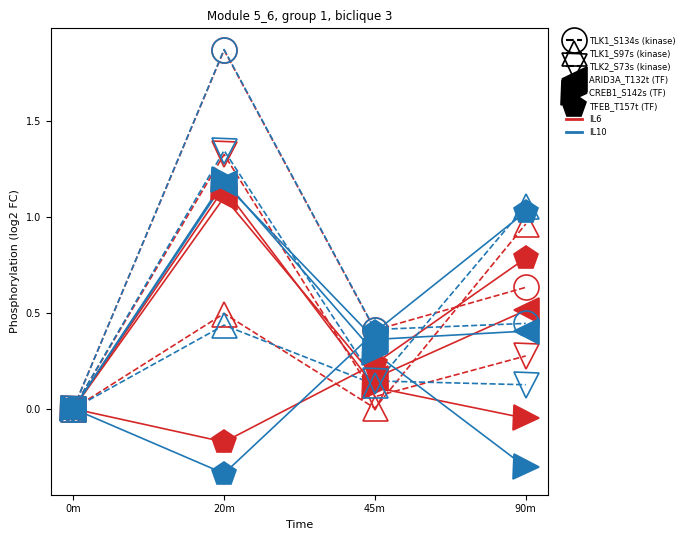

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module5_6_group1_biclique3.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module5_6_group1_biclique3.svg


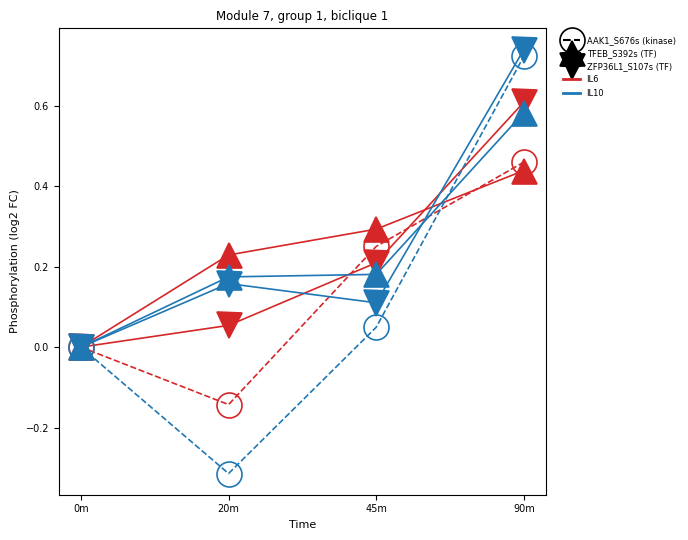

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module7_group1_biclique1.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module7_group1_biclique1.svg


In [11]:
def get_biclique(module, parent_group_idx, biclique_idx):
    matches = [
        g for g in discovered_groups_biclique
        if g["module"] == module and g["parent_group_idx"] == parent_group_idx and g["biclique_idx"] == biclique_idx
    ]
    assert len(matches) == 1, (
        f"Expected exactly 1 biclique for module={module}, parent_group_idx={parent_group_idx}, "
        f"biclique_idx={biclique_idx}, found {len(matches)}"
    )
    return matches[0]


def compute_tf_best_r(module, kinases, tfs):
    """Recomputed fresh from corr_df rather than reusing a biclique's
    stored tf_best_r -- dropping a kinase can change which correlation
    is actually the strongest for a given TF, so this must be
    recalculated against whatever kinase subset ends up in the panel."""
    sub = corr_df[
        (corr_df["module"] == module) &
        (corr_df["kinase_site"].isin(kinases)) &
        (corr_df["tf_site"].isin(tfs))
    ]
    return {tf: sub.loc[sub["tf_site"] == tf, "r"].abs().max() for tf in tfs}


# ---- Panel 1: Module 1, group 2, biclique 1 (was group 1, biclique 3
# before the dedup fix) -- tfs filtered down to ERF_T529t, FOXK1_S243s,
# ZFP91_S106s (CIC_S2311s and HMGXB4_S197s dropped); kinases unchanged
# (already just CDK13_S260s) ----
module1_b1 = get_biclique(1, 2, 1)
module1_tfs_filtered = ["ERF_T529t", "FOXK1_S243s"]
module1_r_filtered = compute_tf_best_r(1, module1_b1["kinases"], module1_tfs_filtered)

# ---- Panel 2: Module 2, group 1, biclique 1 (was biclique 3 before the
# dedup fix) -- kinases filtered down to SRPK2_S490s + SRPK2_S491sT492t
# (CLK1_S101s dropped); tfs unchanged (already just ETV3_S250s) ----
module2_b1 = get_biclique(2, 1, 1)
module2_kinases_filtered = ["SRPK2_S490s", "SRPK2_S491sT492t"]
module2_tfs_filtered = ["ETV3_S250s"]
module2_r_filtered = compute_tf_best_r(2, module2_kinases_filtered, module2_tfs_filtered)

# ---- Panel 3: Module 5_6, group 1, biclique 3 (unchanged) -- tfs
# filtered down to ARID3A_T132t, CREB1_S142s, TFEB_T157t (IKZF1_S461s,
# SON_S1708s, TCF7L2_S35s, WDHD1_S377s dropped); kinases unchanged ----
module5_6_b3 = get_biclique("5_6", 1, 3)
module5_6_tfs_filtered = ["ARID3A_T132t", "CREB1_S142s", "TFEB_T157t"]
module5_6_r_filtered = compute_tf_best_r("5_6", module5_6_b3["kinases"], module5_6_tfs_filtered)

# ---- Panel 4: Module 7, group 1, biclique 1 (unchanged) -- tfs
# filtered down to TFEB_S392s, ZFP36L1_S107s (ARID5A_T37t, ATF7_S248s,
# DNAJC2_T48t, MIER1_S483s dropped); kinases unchanged (already just
# AAK1_S676s) ----
module7_b1 = get_biclique(7, 1, 1)
module7_tfs_filtered = ["TFEB_S392s", "ZFP36L1_S107s"]
module7_r_filtered = compute_tf_best_r(7, module7_b1["kinases"], module7_tfs_filtered)

panels = [
    {"kinases": module1_b1["kinases"], "tfs": module1_tfs_filtered,
     "tf_best_r": module1_r_filtered,
     "title": "Module 1, group 2, biclique 1", "name": "module1_group2_biclique1"},
    {"kinases": module2_kinases_filtered, "tfs": module2_tfs_filtered,
     "tf_best_r": module2_r_filtered,
     "title": "Module 2, group 1, biclique 1", "name": "module2_group1_biclique1"},
    {"kinases": module5_6_b3["kinases"], "tfs": module5_6_tfs_filtered,
     "tf_best_r": module5_6_r_filtered,
     "title": "Module 5_6, group 1, biclique 3", "name": "module5_6_group1_biclique3"},
    {"kinases": module7_b1["kinases"], "tfs": module7_tfs_filtered,
     "tf_best_r": module7_r_filtered,
     "title": "Module 7, group 1, biclique 1", "name": "module7_group1_biclique1"},
]

for panel in panels:
    fig, ax = plt.subplots(figsize=(7, 5.5))
    plot_group_on_ax(ax, panel["kinases"], panel["tfs"], panel["tf_best_r"], panel["title"])
    plt.tight_layout()

    png_out = f"{out_dir}/figures/fig3d_final_{panel['name']}.png"
    svg_out = f"{out_dir}/figures/fig3d_final_{panel['name']}.svg"
    plt.savefig(png_out, dpi=300, bbox_inches="tight")
    plt.savefig(svg_out, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Saved: {png_out}")
    print(f"Saved: {svg_out}")